Códigos sin polígono a 110m (islas pequeñas): ['SGP']


Guardado en D:\EQUIPO\Documents HDD\Tesis\denv-cross-inmunity\figures\mapa_mundial_dengue_silueta.png


Guardado en D:\EQUIPO\Documents HDD\Tesis\denv-cross-inmunity\figures\mapa_mundial_dengue.png


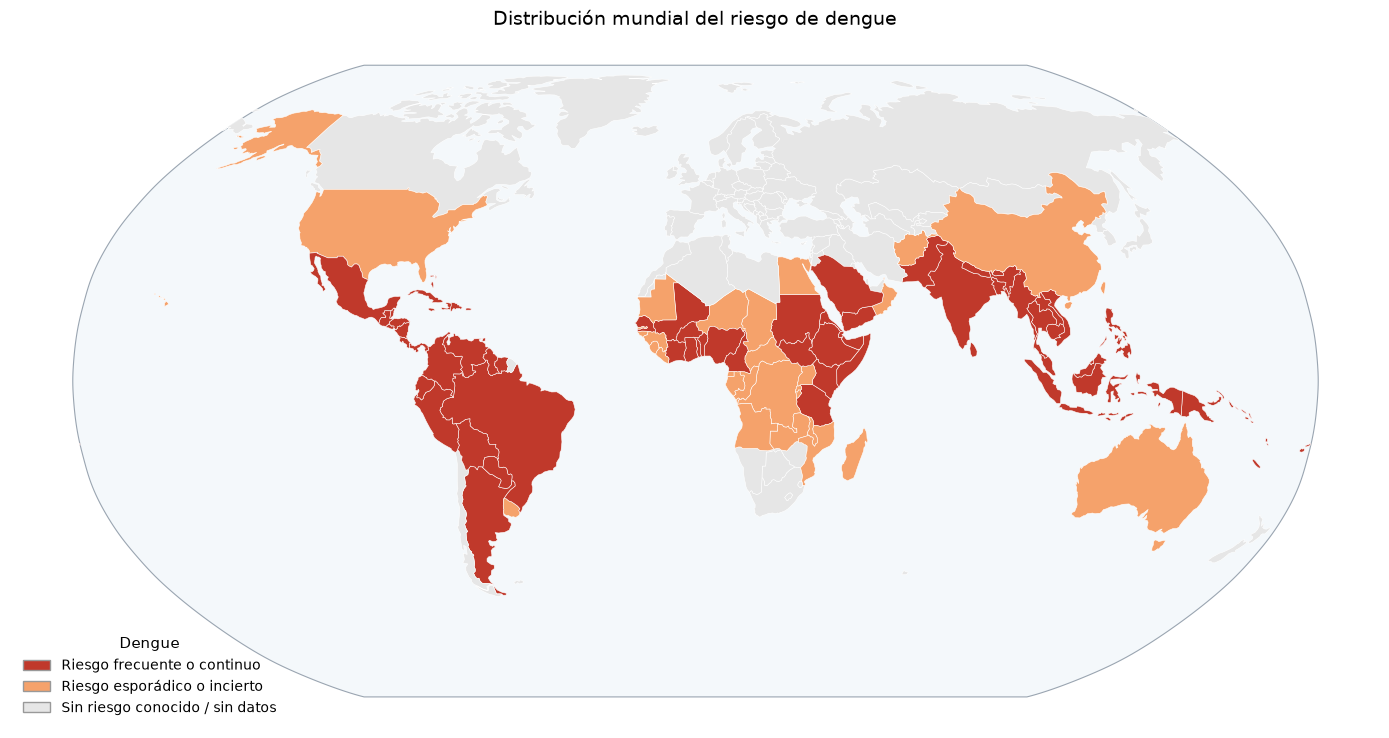

In [1]:
# Mapa mundial de riesgo de dengue (proyección Robinson)
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
from shapely.geometry import Polygon

ROOT = Path.cwd() if (Path.cwd() / "resources").exists() else Path.cwd().parent
NE_ZIP = ROOT / "resources" / "natural_earth" / "ne_110m_admin_0_countries.zip"
OUT = ROOT / "figures" / "mapa_mundial_dengue.png"
OUT_SILUETA = ROOT / "figures" / "mapa_mundial_dengue_silueta.png"

# Clasificación por país (ISO-3), aproximada a partir del mapa de riesgo de dengue
# del CDC Yellow Book y los reportes de la OMS/OPS (2023-2025).
# "frecuente": transmisión frecuente o continua; "esporadico": esporádica o incierta.
FRECUENTE = {
    # Américas
    "MEX", "GTM", "BLZ", "HND", "SLV", "NIC", "CRI", "PAN", "CUB", "DOM", "HTI", "JAM",
    "PRI", "TTO", "BHS", "COL", "VEN", "GUY", "SUR", "BRA", "ECU", "PER", "BOL", "PRY", "ARG",
    # África
    "SDN", "SSD", "ETH", "ERI", "DJI", "SOM", "SOL", "KEN", "TZA", "BFA", "CIV", "GHA", "NGA",
    "CMR", "SEN", "MLI", "TGO", "BEN",
    # Asia y Medio Oriente
    "IND", "PAK", "BGD", "NPL", "BTN", "LKA", "MMR", "THA", "LAO", "KHM", "VNM", "MYS",
    "SGP", "BRN", "IDN", "PHL", "TLS", "SAU", "YEM",
    # Oceanía
    "PNG", "SLB", "VUT", "FJI", "NCL",
}
ESPORADICO = {
    # Américas
    "USA", "URY",
    # África
    "MRT", "GMB", "GNB", "GIN", "SLE", "LBR", "NER", "TCD", "CAF", "GAB", "GNQ", "COG",
    "COD", "UGA", "RWA", "BDI", "AGO", "ZMB", "MWI", "MOZ", "MDG", "EGY",
    # Asia y Medio Oriente
    "CHN", "TWN", "AFG", "OMN",
    # Oceanía
    "AUS",
}

COLORES = {
    "frecuente": "#c0392b",
    "esporadico": "#f5a26b",
    "sin_riesgo": "#e6e6e6",
}
ETIQUETAS = {
    "frecuente": "Riesgo frecuente o continuo",
    "esporadico": "Riesgo esporádico o incierto",
    "sin_riesgo": "Sin riesgo conocido / sin datos",
}

world = gpd.read_file(NE_ZIP)
# Natural Earth deja ISO_A3 = -99 en algunos países (Francia, Noruega...); ADM0_A3 es más completo
iso = world["ISO_A3"].where(world["ISO_A3"] != "-99", world["ADM0_A3"])
world["riesgo"] = "sin_riesgo"
world.loc[iso.isin(ESPORADICO), "riesgo"] = "esporadico"
world.loc[iso.isin(FRECUENTE), "riesgo"] = "frecuente"
world = world[world["ADM0_A3"] != "ATA"]  # sin Antártida

no_encontrados = (FRECUENTE | ESPORADICO) - set(iso)
print("Códigos sin polígono a 110m (islas pequeñas):", sorted(no_encontrados))

world_rob = world.to_crs("ESRI:54030")  # Robinson

fig, ax = plt.subplots(figsize=(14, 7.5))
world_rob.plot(ax=ax, color=world_rob["riesgo"].map(COLORES),
               edgecolor="white", linewidth=0.4)

# Contorno del globo en Robinson
lons = np.r_[np.full(181, -180), np.linspace(-180, 180, 361), np.full(181, 180), np.linspace(180, -180, 361)]
lats = np.r_[np.linspace(-90, 90, 181), np.full(361, 90), np.linspace(90, -90, 181), np.full(361, -90)]
globo = gpd.GeoSeries([Polygon(zip(lons, lats))], crs="EPSG:4326").to_crs("ESRI:54030")
globo.plot(ax=ax, facecolor="#f4f8fb", edgecolor="#9aa5b1", linewidth=0.8, zorder=0)

ax.set_axis_off()
# Solo la silueta: sin leyenda ni título, fondo transparente
fig.savefig(OUT_SILUETA, dpi=300, bbox_inches="tight", pad_inches=0.02, transparent=True)
print("Guardado en", OUT_SILUETA)

ax.legend(handles=[Patch(facecolor=COLORES[k], edgecolor="#999", label=ETIQUETAS[k]) for k in COLORES],
          loc="lower left", frameon=False, fontsize=10, title="Dengue", title_fontsize=11)
ax.set_title("Distribución mundial del riesgo de dengue", fontsize=14)
fig.tight_layout()
fig.savefig(OUT, dpi=300, bbox_inches="tight")
print("Guardado en", OUT)


## Árbol de genotipos de referencia de DENV

Un representante por genotipo, con las ramas pintadas del color de su serotipo.

Representantes canónicos de cada serotipo y genotipo tomados del árbol de
referencia del dataset de Nextclade `nextstrain/dengue/all`, que implementa la
nomenclatura de linajes de Hill et al. (2024). Se conservan
`N_POR_GENOTIPO` secuencias por genotipo y el subárbol inducido se dibuja con
baltic, igual que en `DistancesCalculation.ipynb`.

Las longitudes de rama son las divergencias del build de Nextstrain
(`div` del `tree.json`), escaladas a sustituciones por sitio con la longitud de
la referencia del dataset. Podar el árbol no cambia las distancias entre las
secuencias conservadas.

La versión del dataset está fijada en `NC_TAG` y todo lo descargado queda en
`resources/nextclade_dengue_all/`, de modo que la figura es reproducible.

In [2]:
import json
import random
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from Bio import SeqIO
import baltic as bt

NC_DIR = Path("../resources/nextclade_dengue_all")
VG_DIR = Path("../resources/nextclade_dengue_lineages")
OUT_FIG = Path("../figures")
OUT_TSV = Path("../output")

SERO_COLORS = {1: "#D55E00", 2: "#009E73", 3: "#56B4E9", 4: "#CC79A7"}
COLOR_BACKBONE = "#7F7F7F"   # ramas que mezclan serotipos
N_POR_GENOTIPO = 1
SEMILLA = 20250101

In [3]:
# Descarga del dataset de Nextclade. Solo baja los archivos que falten,
# asi que volver a ejecutar la celda no repite la descarga.
import requests

NC_TAG = "2026-04-14--11-55-23Z"          # version fijada del dataset
NC_BASE = f"https://data.clades.nextstrain.org/v3/nextstrain/dengue/all/{NC_TAG}/"
NC_ARCHIVOS = ["tree.json", "reference.fasta", "genome_annotation.gff3",
               "pathogen.json", "README.md", "CHANGELOG.md"]

NC_DIR.mkdir(parents=True, exist_ok=True)
for nombre in NC_ARCHIVOS:
    destino = NC_DIR / nombre
    if destino.exists():
        print(f"ya estaba: {nombre} ({destino.stat().st_size} bytes)")
        continue
    r = requests.get(NC_BASE + nombre, timeout=180)
    r.raise_for_status()
    destino.write_bytes(r.content)
    print(f"descargado: {nombre} ({len(r.content)} bytes)")

(NC_DIR / "VERSION.txt").write_text(
    f"nextstrain/dengue/all\n{NC_TAG}\n{NC_BASE}\n", encoding="utf8")

# Datasets por serotipo de v-gen-lab (Genome Detective), que asignan el linaje
# de dengue-lineages en clade_membership. Solo se usa su tree.json, para
# derivar la equivalencia entre el genotipo de Nextclade y el linaje nuevo.
VG_TAG = "2026-10-06--17-37-18Z"
VG_BASE = "https://data.clades.nextstrain.org/v3/community/v-gen-lab/dengue/denv{s}/{t}/"

VG_DIR.mkdir(parents=True, exist_ok=True)
for s in SERO_COLORS:
    destino = VG_DIR / f"denv{s}_tree.json"
    if destino.exists():
        print(f"ya estaba: {destino.name} ({destino.stat().st_size} bytes)")
        continue
    r = requests.get(VG_BASE.format(s=s, t=VG_TAG) + "tree.json", timeout=180)
    r.raise_for_status()
    destino.write_bytes(r.content)
    print(f"descargado: {destino.name} ({len(r.content)} bytes)")

(VG_DIR / "VERSION.txt").write_text(
    f"community/v-gen-lab/dengue/denv1-4\n{VG_TAG}\n", encoding="utf8")

ya estaba: tree.json (3442061 bytes)
ya estaba: reference.fasta (10721 bytes)
ya estaba: genome_annotation.gff3 (1741 bytes)
ya estaba: pathogen.json (1910 bytes)
ya estaba: README.md (1087 bytes)
ya estaba: CHANGELOG.md (470 bytes)
ya estaba: denv1_tree.json (663355 bytes)
ya estaba: denv2_tree.json (834534 bytes)
ya estaba: denv3_tree.json (351875 bytes)
ya estaba: denv4_tree.json (450219 bytes)


57

In [4]:
def leer_arbol_auspice(path):
    """Aplana el tree.json de Auspice a una lista de nodos con padre."""
    raiz = json.loads(Path(path).read_text(encoding="utf8"))["tree"]
    nodos, n_id = {}, [0]

    def attr(n, k):
        v = n.get("node_attrs", {}).get(k)
        return v.get("value") if isinstance(v, dict) else v

    def walk(n, padre):
        nid = n.get("name") or f"_n{n_id[0]}"
        n_id[0] += 1
        nodos[nid] = {
            "padre": padre,
            "hijos": [],
            "div": n.get("node_attrs", {}).get("div", 0.0),
            "genotipo": attr(n, "genotype_nextclade"),
            "serotipo": attr(n, "serotype_genbank"),
            "pais": attr(n, "country"),
            "accesion": attr(n, "genbank_accession"),
            "hoja": "children" not in n,
        }
        if padre is not None:
            nodos[padre]["hijos"].append(nid)
        for ch in n.get("children", []):
            walk(ch, nid)
        return nid

    raiz_id = walk(raiz, None)
    return nodos, raiz_id


def mapa_genotipo_a_linaje(nodos):
    """Equivalencia entre el genotipo de Nextclade y el linaje mayor de
    dengue-lineages (Hill et al., 2024).

    No se escribe a mano: se cruzan las accesiones de GenBank del dataset
    `nextstrain/dengue/all`, que trae `genotype_nextclade`, con las de los
    datasets por serotipo de v-gen-lab, que ya asignan el linaje nuevo en
    `clade_membership`. Para cada genotipo se toma el linaje mayoritario.
    """
    por_acc = {}
    for v in nodos.values():
        if v["hoja"] and v["accesion"] and v["genotipo"]:
            por_acc[v["accesion"].split(".")[0]] = v["genotipo"]

    cuentas = {}
    for sero in SERO_COLORS:
        arbol_vg = json.loads((VG_DIR / f"denv{sero}_tree.json").read_text(encoding="utf8"))
        pila = [arbol_vg["tree"]]
        while pila:
            n = pila.pop()
            if "children" in n:
                pila.extend(n["children"])
                continue
            at = n.get("node_attrs", {})
            linaje = at.get("clade_membership", {})
            linaje = linaje.get("value") if isinstance(linaje, dict) else linaje
            acc = (at.get("INSDC_accession") or "")
            acc = acc.get("value") if isinstance(acc, dict) else acc
            acc = (acc or "").split(".")[0]
            if not linaje or linaje == "unassigned" or acc not in por_acc:
                continue
            m = re.match(r"\d+[IVX]+", linaje)          # solo el linaje mayor
            if m:
                cuentas.setdefault(por_acc[acc], Counter())[m.group(0)] += 1

    tabla = pd.DataFrame([
        {"genotipo_nextclade": g, "linaje_dengue_lineages": c.most_common(1)[0][0],
         "n_apoyo": c.most_common(1)[0][1], "n_total": sum(c.values()),
         "otros": ", ".join(f"{k}:{v}" for k, v in c.most_common()[1:]) or "-"}
        for g, c in sorted(cuentas.items())
    ])
    return dict(zip(tabla["genotipo_nextclade"], tabla["linaje_dengue_lineages"])), tabla


def elegir_representantes(nodos, n_por_genotipo, semilla):
    """n secuencias por genotipo, preferiendo las que traen accesion de GenBank."""
    hojas = {k: v for k, v in nodos.items() if v["hoja"] and v["genotipo"]}
    rng = random.Random(semilla)
    elegidas = []
    for gen in sorted({v["genotipo"] for v in hojas.values()}):
        cand = sorted(k for k, v in hojas.items() if v["genotipo"] == gen)
        con_acc = [k for k in cand if hojas[k]["accesion"]]
        pool = con_acc if len(con_acc) >= n_por_genotipo else cand
        elegidas += rng.sample(pool, min(n_por_genotipo, len(pool)))
    return set(elegidas)


def podar_a_newick(nodos, raiz, conservar, n_sitios):
    """Newick del subarbol inducido por las hojas conservadas.
    Las longitudes de rama son diferencias de div, asi que las distancias
    entre las hojas conservadas son las mismas del arbol completo."""
    vivos = set()
    for h in conservar:
        k = h
        while k is not None and k not in vivos:
            vivos.add(k)
            k = nodos[k]["padre"]

    def construir(k, div_padre):
        hijos = [c for c in nodos[k]["hijos"] if c in vivos]
        largo = (nodos[k]["div"] - div_padre) / n_sitios
        if not hijos:
            return f"{k.replace(':', '_').replace(',', '_').replace(' ', '_')}:{largo:.8f}"
        if len(hijos) == 1:                      # colapsa nodos de un solo hijo
            return construir(hijos[0], div_padre)
        partes = ",".join(construir(c, nodos[k]["div"]) for c in hijos)
        return f"({partes}):{largo:.8f}"

    return construir(raiz, nodos[raiz]["div"]) + ";"


def dibujar_arbol(ax, arbol, color, grosor, tam_punta=110, zorder=10):
    """Dibuja el arbol desde k.x / k.y de baltic, como en DistancesCalculation."""
    segs, cols, anchos = [], [], []
    px, py, pc = [], [], []
    for k in arbol.Objects:
        x, y = k.x, k.y
        x_padre = getattr(getattr(k, "parent", None), "x", None)
        if x_padre is None:
            x_padre = x
        c, w = color(k), grosor(k)
        segs.append([(x_padre, y), (x, y)])
        cols.append(c)
        anchos.append(w)
        if k.branchType == "node":
            ys = [ch.y for ch in k.children]
            segs.append([(x, min(ys)), (x, max(ys))])
            cols.append(c)
            anchos.append(w)
        else:
            px.append(x)
            py.append(y)
            pc.append(c)
    ax.add_collection(LineCollection(segs, colors=cols, linewidths=anchos,
                                     capstyle="round", zorder=zorder))
    ax.scatter(px, py, s=tam_punta, c=pc, edgecolors="#333333",
               linewidths=0.9, zorder=zorder + 2)
    ax.autoscale_view()

### Nomenclatura, representantes y figura

Las puntas se etiquetan con el linaje mayor de **dengue-lineages**
(Hill et al., 2024), en números romanos: nada de `Cosmopolitan` ni `American`.
La equivalencia entre el genotipo de Nextclade y el linaje nuevo no se escribe
a mano: se deriva cruzando las accesiones de GenBank de los dos conjuntos de
datos y se guarda en `output/equivalencia_genotipo_linaje.tsv`.

La tabla de representantes, con accesión, país, genotipo y linaje, queda en
`output/genotipos_referencia_nextclade.tsv`.

genotipo_nextclade linaje_dengue_lineages  n_apoyo  n_total  otros
           DENV1/I                     1I       14       14      -
          DENV1/II                    1II        3        3      -
         DENV1/III                   1III        4        5   1V:1
          DENV1/IV                    1IV        6        6      -
           DENV1/V                     1V       19       25 1VII:6
          DENV2/AA                   2III       26       26      -
          DENV2/AI                     2V        3        3      -
         DENV2/AII                    2IV        2        2      -
          DENV2/AM                     2I        2        2      -
           DENV2/C                    2II       18       18      -
           DENV2/S                    2VI        3        4   2I:1
           DENV3/I                     3I        8        8      -
          DENV3/II                    3II       10       10      -
         DENV3/III                   3III        9        9   

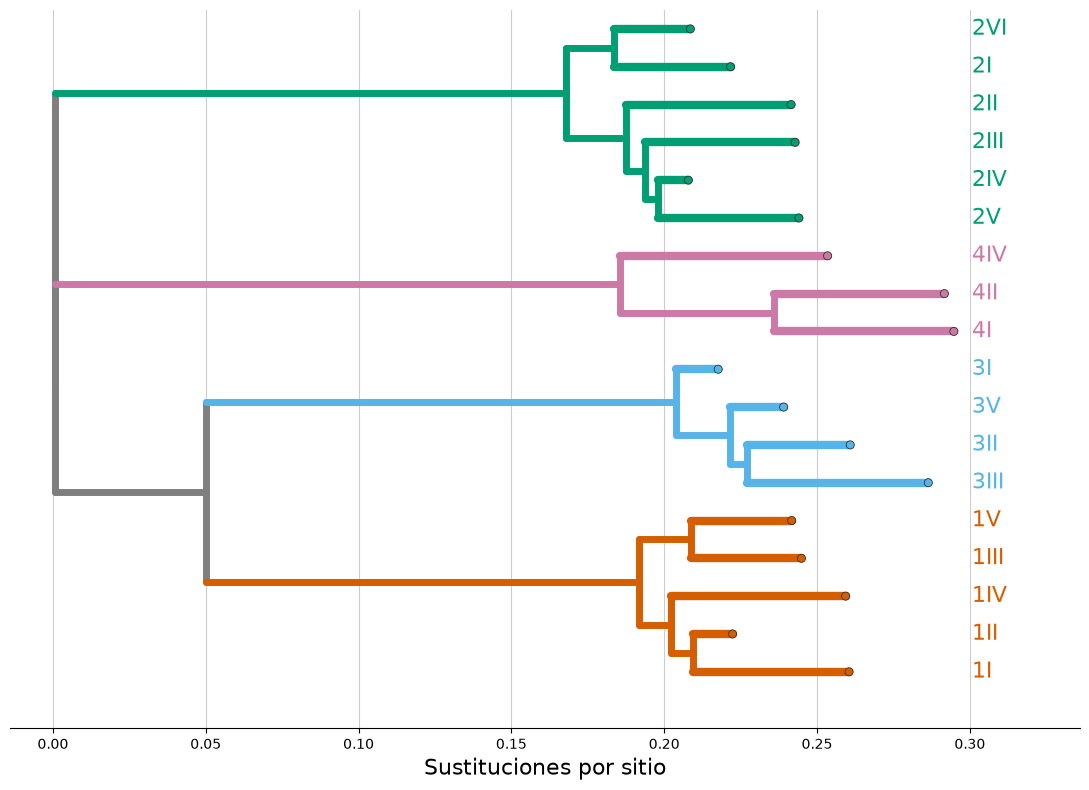

In [11]:
nodos, raiz = leer_arbol_auspice(NC_DIR / "tree.json")

linaje_de, tabla_equivalencias = mapa_genotipo_a_linaje(nodos)
OUT_TSV.mkdir(exist_ok=True)
tabla_equivalencias.to_csv(OUT_TSV / "equivalencia_genotipo_linaje.tsv",
                           sep="\t", index=False)
print(tabla_equivalencias.to_string(index=False))

conservar = elegir_representantes(nodos, N_POR_GENOTIPO, SEMILLA)
print(f"{len(conservar)} representantes de "
      f"{len({nodos[k]['genotipo'] for k in conservar})} genotipos")

# Tabla de representantes, para citar las accesiones en la tesis.
reps = pd.DataFrame([
    {"nombre": k, "linaje": linaje_de.get(nodos[k]["genotipo"], "?"),
     "genotipo_nextclade": nodos[k]["genotipo"],
     "serotipo": nodos[k]["serotipo"], "pais": nodos[k]["pais"],
     "accesion": nodos[k]["accesion"], "div": nodos[k]["div"]}
    for k in sorted(conservar, key=lambda k: (nodos[k]["genotipo"], k))
])
reps.to_csv(OUT_TSV / "genotipos_referencia_nextclade.tsv", sep="\t", index=False)
print(reps.to_string(index=False))

# div viene en sustituciones sobre todo el genoma; se pasa a sustituciones
# por sitio dividiendo por la longitud de la referencia del dataset.
n_sitios = len(next(SeqIO.parse(NC_DIR / "reference.fasta", "fasta")).seq)
print(f"Referencia del dataset: {n_sitios} nt")

newick = podar_a_newick(nodos, raiz, conservar, n_sitios)
nwk_path = NC_DIR / "arbol_genotipos_podado.nwk"
nwk_path.write_text(newick, encoding="utf8")

arbol = bt.load_newick(str(nwk_path), treeType="divergence")
arbol.traverse_tree()
arbol.sort_branches()

# Serotipo y genotipo de cada hoja, por el nombre saneado del newick.
clave = {k.replace(":", "_").replace(",", "_").replace(" ", "_"): k
         for k in conservar}
info = {}
for k in arbol.Objects:
    if k.branchType == "leaf":
        orig = clave[k.name]
        info[k.name] = (int(nodos[orig]["serotipo"].replace("denv", "")),
                        nodos[orig]["genotipo"])

def hojas_de(k):
    if k.branchType == "leaf":
        return [k.name]
    return [d.name if hasattr(d, "name") else d for d in k.leaves]

def color_sero(k):
    s = {info[h][0] for h in hojas_de(k) if h in info}
    return SERO_COLORS[s.pop()] if len(s) == 1 else COLOR_BACKBONE

def grosor(k):
    return 6.0 if k.branchType == "leaf" else 5.0

fig, ax = plt.subplots(figsize=(11, 8))
dibujar_arbol(ax, arbol, color_sero, grosor)

# Una punta por genotipo: la etiqueta es el linaje mayor de dengue-lineages.
x_max = max(k.x for k in arbol.Objects)
for k in arbol.get_external():
    s, g = info[k.name]
    ax.text(x_max * 1.02, k.y, linaje_de.get(g, g), va="center", ha="left",
            fontsize=16, color=SERO_COLORS[s])

ax.set_xlabel("Sustituciones por sitio", fontsize=16)
ax.set_yticks([])
ax.grid(axis="x", color="#CCCCCC", lw=0.8)
ax.set_axisbelow(True)
for lado in ["top", "right", "left"]:
    ax.spines[lado].set_visible(False)
ax.set_ylim(-1, len(arbol.get_external()))
ax.set_xlim(right=x_max * 1.14)

fig.tight_layout()
OUT_FIG.mkdir(exist_ok=True)
fig.savefig(OUT_FIG / "arbol_genotipos_referencia.png", dpi=300,
            bbox_inches="tight")
print("Guardado:", OUT_FIG / "arbol_genotipos_referencia.png")